In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [14]:
df = pd.read_csv('wine_data.csv', header=None, usecols=[0,1,2])
df.columns = ['Class Label', 'Alcohol', 'Malic Acid']

In [15]:
df.shape

(178, 3)

In [16]:
df.head()

,Class Label,Alcohol,Malic Acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59


In [17]:
df.shape

(178, 3)

C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='Alcohol', ylabel='Density'>

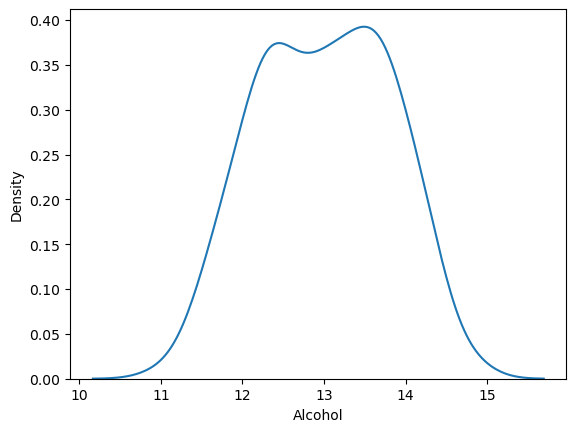

In [19]:
sns.kdeplot(df['Alcohol'])

C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='Malic Acid', ylabel='Density'>

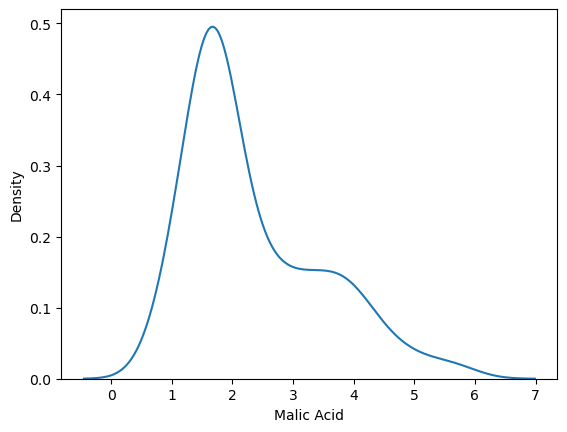

In [20]:
sns.kdeplot(df['Malic Acid'])

<Axes: xlabel='Alcohol', ylabel='Malic Acid'>

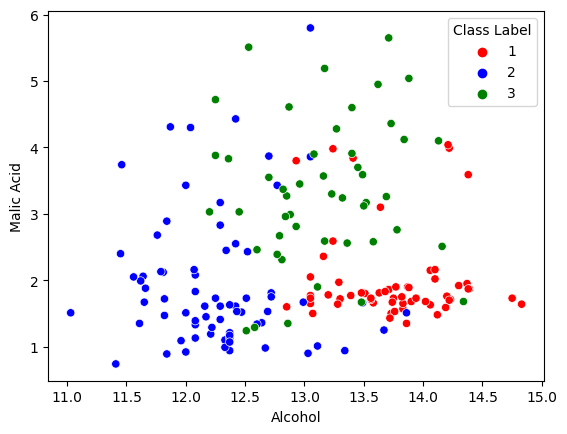

In [25]:
color_dict = {1:'red', 2:'blue', 3:'green'}
sns.scatterplot(x=df['Alcohol'], y=df['Malic Acid'], data = df,
                hue = df['Class Label'], palette = color_dict)

In [23]:
df.head(2)

,Class Label,Alcohol,Malic Acid
0,1,14.23,1.71
1,1,13.20,1.78


In [24]:
df['Class Label'].value_counts()

Class Label
2    71
1    59
3    48
Name: count, dtype: int64

In [27]:
from sklearn.model_selection import train_test_split 
X_train, X_test, y_train, y_test = train_test_split(df.drop(['Class Label'],
                                                   axis = 1),
                                                   df['Class Label'],
                                                   test_size=0.3,
                                                   random_state = 0)

In [28]:
X_train.shape

(124, 2)

In [29]:
X_test.shape

(54, 2)

In [30]:
y_train.shape

(124,)

In [31]:
y_test.shape

(54,)

In [32]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test) 

In [33]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns = X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns = X_test.columns)


In [34]:
X_train_scaled.head(2)

,Alcohol,Malic Acid
0,0.720430,0.203782
1,0.319892,0.084034


In [35]:
X_train.describe()

,Alcohol,Malic Acid
count,124.000000,124.000000
mean,12.983065,2.383710
std,0.801340,1.136696
min,11.030000,0.890000
25%,12.362500,1.607500
50%,13.040000,1.885000
75%,13.640000,3.247500
max,14.750000,5.650000


In [36]:
np.round(X_train.describe(), 1)

,Alcohol,Malic Acid
count,124.0,124.0
mean,13.0,2.4
std,0.8,1.1
min,11.0,0.9
25%,12.4,1.6
50%,13.0,1.9
75%,13.6,3.2
max,14.8,5.6


In [37]:
np.round(X_train_scaled.describe(), 1)

,Alcohol,Malic Acid
count,124.0,124.0
mean,0.5,0.3
std,0.2,0.2
min,0.0,0.0
25%,0.4,0.2
50%,0.5,0.2
75%,0.7,0.5
max,1.0,1.0


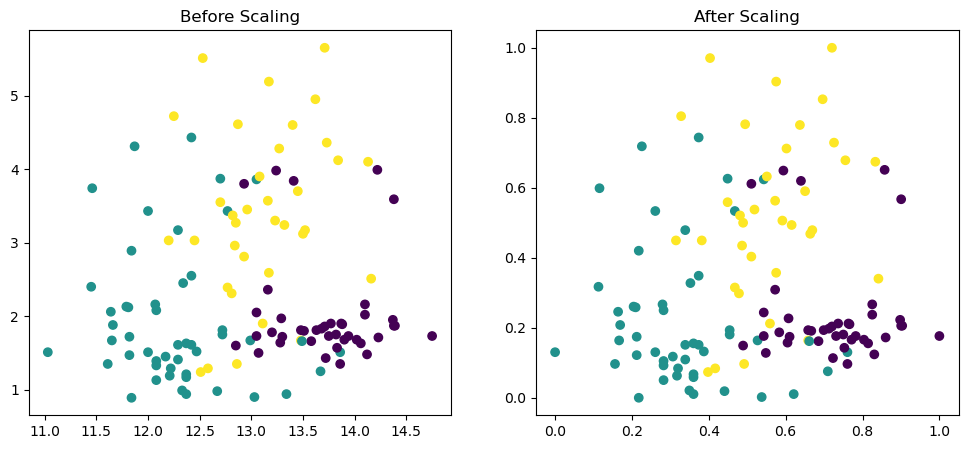

In [38]:
fig, (ax1,ax2) = plt.subplots(ncols = 2, figsize =(12,5))
ax1.scatter(X_train['Alcohol'], X_train['Malic Acid'], c = y_train)
ax1.set_title('Before Scaling')
ax2.scatter(X_train_scaled['Alcohol'], X_train_scaled['Malic Acid'], c =y_train)
ax2.set_title('After Scaling')
plt.show()

In [40]:
y_train.head(10)

22     1
108    2
175    3
145    3
71     2
162    3
156    3
27     1
83     2
134    3
Name: Class Label, dtype: int64

In [41]:
df.head(2)

,Class Label,Alcohol,Malic Acid
0,1,14.23,1.71
1,1,13.20,1.78


C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating ins

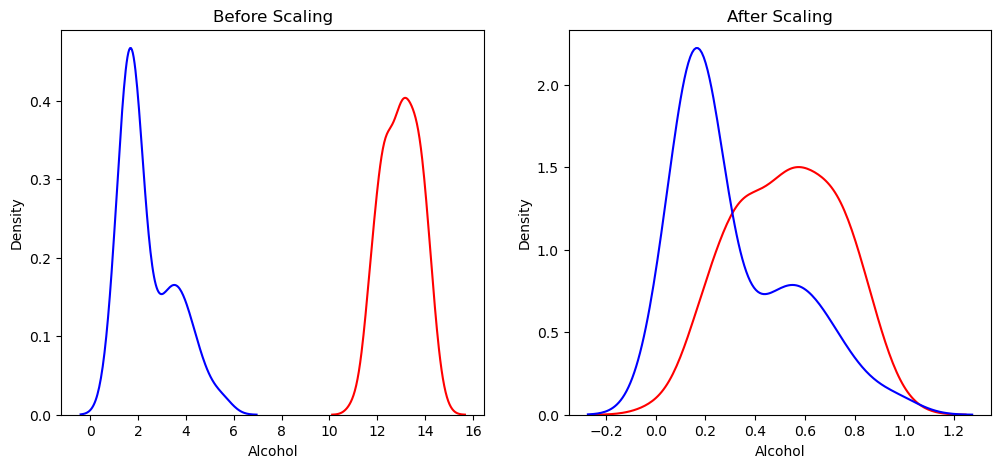

In [49]:
fig, (ax1,ax2) = plt.subplots(ncols = 2, figsize =(12,5))
ax1.set_title('Before Scaling')
sns.kdeplot(X_train['Alcohol'], ax = ax1, color = 'red')
sns.kdeplot(X_train['Malic Acid'], ax = ax1, color ='blue')

ax2.set_title('After Scaling')
sns.kdeplot(X_train_scaled['Alcohol'], ax = ax2, color = 'red')
sns.kdeplot(X_train_scaled['Malic Acid'], ax = ax2, color = 'blue')
plt.show()

C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\dell\AppData\Local\Temp\ipykernel_6116\1706807397.py:6: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


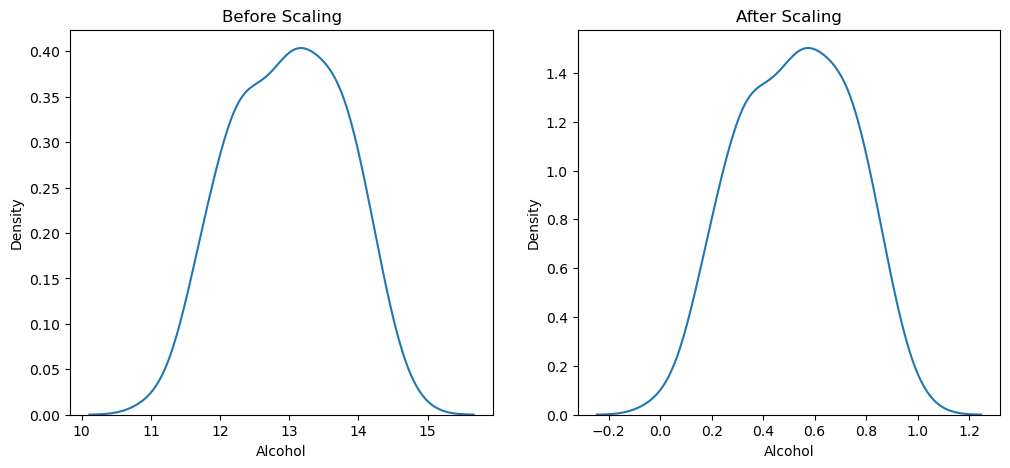

In [50]:
fig, (ax1,ax2) = plt.subplots(ncols =2, figsize = (12,5))
ax1.set_title('Before Scaling')
sns.kdeplot(X_train['Alcohol'], ax = ax1)
ax2.set_title('After Scaling')
sns.kdeplot(X_train_scaled['Alcohol'], ax = ax2)
fig.show()

C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\dell\AppData\Local\Temp\ipykernel_6116\1452840050.py:6: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


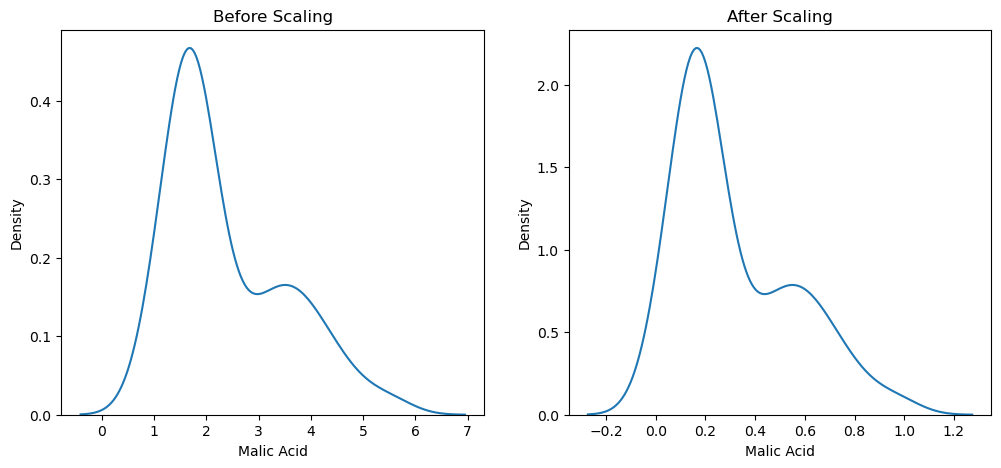

In [51]:
fig, (ax1,ax2) = plt.subplots(ncols =2, figsize = (12,5))
ax1.set_title('Before Scaling')
sns.kdeplot(X_train['Malic Acid'], ax = ax1)
ax2.set_title('After Scaling')
sns.kdeplot(X_train_scaled['Malic Acid'], ax = ax2)
fig.show()